# History-Aware Model with Cialdini Features

This notebook evaluates whether explicitly extracted Cialdini persuasion features improve phishing detection beyond conversation history alone.

The model combines:

1. TF-IDF features from cumulative conversation history.
2. Current and cumulative Cialdini persuasion features.

The same conversation-level partitions and logistic-regression settings used for the baseline models are retained for a controlled comparison.

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

In [3]:
current_folder = Path.cwd()

if current_folder.name == "notebooks":
    project_root = current_folder.parent
else:
    project_root = current_folder

feature_path = (
    project_root
    / "data"
    / "processed"
    / "turn_level_cialdini_features.csv"
)

partition_path = (
    project_root
    / "data"
    / "processed"
    / "conversation_partitions.csv"
)

print("Feature file exists:", feature_path.exists())
print("Partition file exists:", partition_path.exists())

Feature file exists: True
Partition file exists: True


In [4]:
feature_df = pd.read_csv(feature_path)
partition_df = pd.read_csv(partition_path)

model_df = feature_df.merge(
    partition_df[
        ["conversation_id", "partition"]
    ],
    on="conversation_id",
    how="left",
    validate="many_to_one",
)

print("Rows:", len(model_df))
print("Conversations:", model_df["conversation_id"].nunique())
print("Missing partitions:", model_df["partition"].isna().sum())

print("\nTurns by partition:")
print(model_df["partition"].value_counts())

Rows: 14850
Conversations: 1350
Missing partitions: 0

Turns by partition:
partition
test          9900
train         3960
validation     990
Name: count, dtype: int64


## Validate Cialdini Model Features

Only cumulative conversation text and the independently extracted Cialdini variables are included. Supplied SE-VSim metadata, including personality traits, attack strategies, rationales, and attack outcomes, remains excluded.

In [5]:
cialdini_feature_columns = [
    column
    for column in model_df.columns
    if column.endswith("_present")
    or column.endswith("_count")
]

print("Number of Cialdini feature columns:",
      len(cialdini_feature_columns))

for column in cialdini_feature_columns:
    print("-", column)

Number of Cialdini feature columns: 24
- authority_present
- authority_count
- scarcity_present
- scarcity_count
- reciprocity_present
- reciprocity_count
- commitment_consistency_present
- commitment_consistency_count
- liking_present
- liking_count
- social_proof_present
- social_proof_count
- authority_cumulative_count
- authority_cumulative_present
- scarcity_cumulative_count
- scarcity_cumulative_present
- reciprocity_cumulative_count
- reciprocity_cumulative_present
- commitment_consistency_cumulative_count
- commitment_consistency_cumulative_present
- liking_cumulative_count
- liking_cumulative_present
- social_proof_cumulative_count
- social_proof_cumulative_present


In [6]:
print(
    "Missing Cialdini values:",
    model_df[cialdini_feature_columns]
    .isna()
    .sum()
    .sum()
)

print(
    "Non-numeric Cialdini columns:",
    model_df[cialdini_feature_columns]
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

print(
    "Negative Cialdini values:",
    (
        model_df[cialdini_feature_columns] < 0
    ).sum().sum()
)

Missing Cialdini values: 0
Non-numeric Cialdini columns: []
Negative Cialdini values: 0


## Train the Cialdini-Augmented Model

The model combines TF-IDF representations of cumulative conversation history with the 24 current and cumulative Cialdini features. The classifier and textual settings match the history-aware baseline.

In [7]:
train_df = model_df[
    model_df["partition"] == "train"
].copy()

validation_df = model_df[
    model_df["partition"] == "validation"
].copy()

model_input_columns = [
    "cumulative_history",
    *cialdini_feature_columns,
]

X_train = train_df[model_input_columns]
y_train = train_df["label"].astype(int)

X_validation = validation_df[model_input_columns]
y_validation = validation_df["label"].astype(int)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_validation))
print("Input columns:", len(model_input_columns))

Training examples: 3960
Validation examples: 990
Input columns: 25


In [8]:
feature_processor = ColumnTransformer([
    (
        "history_text",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True,
        ),
        "cumulative_history",
    ),
    (
        "cialdini_features",
        StandardScaler(),
        cialdini_feature_columns,
    ),
])

cialdini_model = Pipeline([
    ("features", feature_processor),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
        ),
    ),
])

cialdini_model.fit(
    X_train,
    y_train,
)

print("Cialdini-augmented model training complete.")

Cialdini-augmented model training complete.


In [14]:
def evaluate_predictions(y_true, y_pred, model_name):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "false_positive_rate": fp / (fp + tn),
        "false_negative_rate": fn / (fn + tp),
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
    }

In [15]:
cialdini_validation_predictions = (
    cialdini_model.predict(X_validation)
)

cialdini_validation_results = evaluate_predictions(
    y_validation,
    cialdini_validation_predictions,
    "History + Cialdini",
)

display(
    pd.DataFrame(
        [cialdini_validation_results]
    ).round(4)
)

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        cialdini_validation_predictions,
        target_names=["Benign", "Malicious"],
        zero_division=0,
    )
)

print("Confusion matrix:")
print(
    confusion_matrix(
        y_validation,
        cialdini_validation_predictions,
        labels=[0, 1],
    )
)

,model,accuracy,precision,recall,f1_score,false_positive_rate,false_negative_rate,true_negatives,false_positives,false_negatives,true_positives
0,History + Cialdini,0.8202,0.8347,0.9106,0.871,0.3606,0.0894,211,119,59,601



Classification report:
              precision    recall  f1-score   support

      Benign       0.78      0.64      0.70       330
   Malicious       0.83      0.91      0.87       660

    accuracy                           0.82       990
   macro avg       0.81      0.78      0.79       990
weighted avg       0.82      0.82      0.82       990

Confusion matrix:
[[211 119]
 [ 59 601]]


In [16]:
unscaled_feature_processor = ColumnTransformer([
    (
        "history_text",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True,
        ),
        "cumulative_history",
    ),
    (
        "cialdini_features",
        "passthrough",
        cialdini_feature_columns,
    ),
])

unscaled_cialdini_model = Pipeline([
    ("features", unscaled_feature_processor),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
        ),
    ),
])

unscaled_cialdini_model.fit(
    X_train,
    y_train,
)

unscaled_validation_predictions = (
    unscaled_cialdini_model.predict(X_validation)
)

unscaled_validation_results = evaluate_predictions(
    y_validation,
    unscaled_validation_predictions,
    "History + unscaled Cialdini",
)

display(
    pd.DataFrame(
        [unscaled_validation_results]
    ).round(4)
)

print(
    confusion_matrix(
        y_validation,
        unscaled_validation_predictions,
        labels=[0, 1],
    )
)

,model,accuracy,precision,recall,f1_score,false_positive_rate,false_negative_rate,true_negatives,false_positives,false_negatives,true_positives
0,History + unscaled Cialdini,0.8202,0.8347,0.9106,0.871,0.3606,0.0894,211,119,59,601


[[211 119]
 [ 59 601]]


In [17]:
development_df = model_df[
    model_df["partition"].isin(["train", "validation"])
].copy()

test_df = model_df[
    model_df["partition"] == "test"
].copy()

X_development = development_df[model_input_columns]
y_development = development_df["label"].astype(int)

X_test = test_df[model_input_columns]
y_test = test_df["label"].astype(int)

print("Development examples:", len(X_development))
print("Test examples:", len(X_test))

Development examples: 4950
Test examples: 9900


In [18]:
from sklearn.base import clone

final_cialdini_model = clone(
    unscaled_cialdini_model
)

final_cialdini_model.fit(
    X_development,
    y_development,
)

cialdini_test_predictions = (
    final_cialdini_model.predict(X_test)
)

cialdini_test_results = evaluate_predictions(
    y_test,
    cialdini_test_predictions,
    "History + Cialdini",
)

display(
    pd.DataFrame(
        [cialdini_test_results]
    ).round(4)
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        cialdini_test_predictions,
        target_names=["Benign", "Malicious"],
        zero_division=0,
    )
)

print("Confusion matrix:")
print(
    confusion_matrix(
        y_test,
        cialdini_test_predictions,
        labels=[0, 1],
    )
)

,model,accuracy,precision,recall,f1_score,false_positive_rate,false_negative_rate,true_negatives,false_positives,false_negatives,true_positives
0,History + Cialdini,0.8367,0.8534,0.9117,0.8815,0.3133,0.0883,2266,1034,583,6017



Classification report:
              precision    recall  f1-score   support

      Benign       0.80      0.69      0.74      3300
   Malicious       0.85      0.91      0.88      6600

    accuracy                           0.84      9900
   macro avg       0.82      0.80      0.81      9900
weighted avg       0.83      0.84      0.83      9900

Confusion matrix:
[[2266 1034]
 [ 583 6017]]


In [19]:
results_folder = project_root / "results"

baseline_results_path = (
    results_folder
    / "baseline_test_results.csv"
)

baseline_test_results = pd.read_csv(
    baseline_results_path
)

all_model_test_results = pd.concat(
    [
        baseline_test_results,
        pd.DataFrame([cialdini_test_results]),
    ],
    ignore_index=True,
)

comparison_columns = [
    "model",
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "false_positive_rate",
    "false_negative_rate",
    "true_negatives",
    "false_positives",
    "false_negatives",
    "true_positives",
]

all_model_test_results = all_model_test_results[
    comparison_columns
]

display(all_model_test_results.round(4))

,model,accuracy,precision,recall,f1_score,false_positive_rate,false_negative_rate,true_negatives,false_positives,false_negatives,true_positives
0,Single-turn baseline,0.7796,0.8358,0.8330,0.8344,0.3273,0.1670,2220,1080,1102,5498
1,History-aware baseline,0.8460,0.8543,0.9271,0.8892,0.3164,0.0729,2256,1044,481,6119
2,History + Cialdini,0.8367,0.8534,0.9117,0.8815,0.3133,0.0883,2266,1034,583,6017


In [20]:
comparison_path = (
    results_folder
    / "all_model_test_results.csv"
)

all_model_test_results.to_csv(
    comparison_path,
    index=False,
)

print("Saved to:", comparison_path)

Saved to: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\results\all_model_test_results.csv


## Save Three-Model Predictions

Predictions from all three model conditions are combined using conversation and turn identifiers. This supports later analysis of which examples changed classification after conversational history or Cialdini features were added.

In [21]:
baseline_prediction_path = (
    results_folder
    / "baseline_test_predictions.csv"
)

baseline_predictions = pd.read_csv(
    baseline_prediction_path
)

ordered_test_df = test_df.reset_index(drop=True)
baseline_predictions = baseline_predictions.reset_index(drop=True)

print(
    "Matching row counts:",
    len(baseline_predictions) == len(ordered_test_df)
)

print(
    "Matching conversation IDs:",
    baseline_predictions["conversation_id"].equals(
        ordered_test_df["conversation_id"]
    )
)

print(
    "Matching turn numbers:",
    baseline_predictions["turn_number"].equals(
        ordered_test_df["turn_number"]
    )
)

Matching row counts: True
Matching conversation IDs: True
Matching turn numbers: True


In [22]:
all_model_predictions = baseline_predictions.copy()

all_model_predictions["cialdini_prediction"] = (
    cialdini_test_predictions
)

all_model_predictions["cialdini_probability"] = (
    final_cialdini_model.predict_proba(X_test)[:, 1]
)

all_predictions_path = (
    results_folder
    / "all_model_test_predictions.csv"
)

all_model_predictions.to_csv(
    all_predictions_path,
    index=False,
)

print("Saved to:", all_predictions_path)
print("Saved rows:", len(all_model_predictions))
print(
    "Missing values:",
    all_model_predictions.isna().sum().sum()
)

Saved to: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\results\all_model_test_predictions.csv
Saved rows: 9900
Missing values: 0


## Three-Model Confusion Matrix Comparison

Confusion matrices compare benign and malicious classifications across the single-turn, history-aware, and Cialdini-augmented conditions.

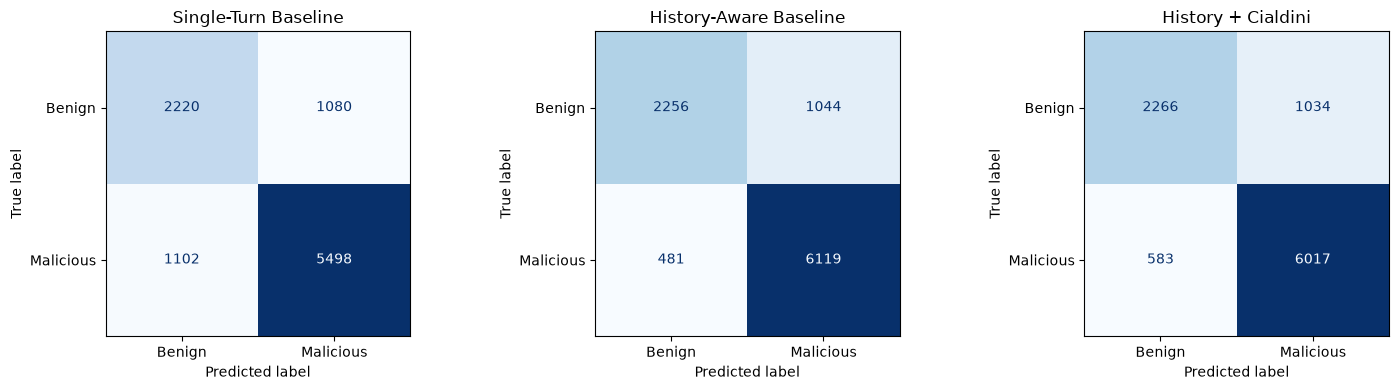

Saved to: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\results\all_model_confusion_matrices.png


In [23]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4),
)

model_predictions = [
    (
        "Single-Turn Baseline",
        all_model_predictions["single_turn_prediction"],
    ),
    (
        "History-Aware Baseline",
        all_model_predictions["history_prediction"],
    ),
    (
        "History + Cialdini",
        all_model_predictions["cialdini_prediction"],
    ),
]

for axis, (model_name, predictions) in zip(
    axes,
    model_predictions,
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Benign", "Malicious"],
        cmap="Blues",
        colorbar=False,
        ax=axis,
    )

    axis.set_title(model_name)

plt.tight_layout()

comparison_figure_path = (
    results_folder
    / "all_model_confusion_matrices.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved to:", comparison_figure_path)

## Final Augmented-Model Validation

The completed experiment is checked for prediction completeness, valid binary outputs, consistent test-set size, and exclusion of privileged SE-VSim metadata.

In [24]:
excluded_metadata = {
    "trait",
    "attack_success",
    "rationale",
    "attack_strategies",
    "scenario_class",
    "information_class",
}

final_model_checks = {
    "test_prediction_rows": len(all_model_predictions),
    "missing_prediction_values": (
        all_model_predictions.isna().sum().sum()
    ),
    "invalid_cialdini_predictions": (
        ~all_model_predictions[
            "cialdini_prediction"
        ].isin([0, 1])
    ).sum(),
    "cialdini_feature_count": len(
        cialdini_feature_columns
    ),
    "excluded_metadata_inputs": len(
        excluded_metadata.intersection(
            model_input_columns
        )
    ),
    "models_in_comparison": len(
        all_model_test_results
    ),
}

final_model_checks_df = pd.DataFrame(
    final_model_checks.items(),
    columns=["check", "value"],
)

final_model_checks_df

,check,value
0,test_prediction_rows,9900
1,missing_prediction_values,0
2,invalid_cialdini_predictions,0
3,cialdini_feature_count,24
4,excluded_metadata_inputs,0
5,models_in_comparison,3


In [25]:
checks_path = (
    results_folder
    / "cialdini_model_validation_checks.csv"
)

final_model_checks_df.to_csv(
    checks_path,
    index=False,
)

print("Saved to:", checks_path)

Saved to: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\results\cialdini_model_validation_checks.csv
